In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
plt.style.use('default')


## `Problem 1 to 5`:

Dataset link: https://tinyurl.com/2fe6vz4u

**Add a label to every axis and add a proper title for the charts. Also add proper labels if there are multiple representations.** Then, you can customize it as your wish.

### **`Problem-1:`** Draw a line plot of which, the x-axis is the "Year" and the y-axis is sum of "PM2.5" of two countries Iran and China.

In [ ]:
# code here
df = pd.read_csv('https://tinyurl.com/2fe6vz4u')
df.head()

In [ ]:
import pandas as pd

# Read the dataset
df = pd.read_csv('https://tinyurl.com/2fe6vz4u')

# Preview the data
df.head()

# PM2.5 yearly sum for Iran
iran_series = (
    df.query('Country == "Iran"')
      .groupby('Year')['PM2.5']
      .sum()
)

# PM2.5 yearly sum for China
china_series = (
    df.query('Country == "China"')
      .groupby('Year')['PM2.5']
      .sum()
)

# Display results
print("Iran PM2.5 by Year:")
print(iran_series)

print("\nChina PM2.5 by Year:")
print(china_series)


In [ ]:
plt.plot(iran_series.index,iran_series.values,label='Iran',linestyle='dashed')
plt.plot(china_series.index,china_series.values,label='China',linestyle='dotted',color='red')
plt.xlabel('Year')
plt.ylabel('PM2.5') 
plt.title('PM2.5 Over the years')
plt.xticks(df['Year'].value_counts().index)
plt.legend()
plt.grid()
plt.show()

### **`Problem-2:`** Draw a histogram of the  column "PM10" of which the y-axis represents the probability (see the documentation how to draw the probability).

In [ ]:
# code here
plt.hist(df['PM10'],density=True,bins=50,facecolor='green',alpha=0.6)
plt.xlabel('Bins')
plt.ylabel('Probability')
plt.title('Histogram of PM10')
plt.grid()
plt.show()

### **`Problem-3:`** Draw a scatter plot where x-axis represents "PM2.5" and y-axis represents "PM10" for two countries Poland and Chile.

In [ ]:
# code here
chile_df = df.query("Country == 'Chile'")
poland_df = df.query("Country == 'Poland'")
chile_df
poland_df

In [ ]:
plt.scatter(chile_df['PM2.5'],chile_df['PM10'],marker="+",color='red',label='Chile')
plt.scatter(poland_df['PM2.5'],poland_df['PM10'],marker="D",color='yellow',label='Poland')
plt.xlabel('PM2.5')
plt.ylabel('PM10')
plt.title('PM2.5 Vs PM10 for Chile and Poland')
plt.legend()
plt.grid()
plt.show()

### **`Problem-4:`** Draw a pie chart of top 5 most frequent countries.

In [ ]:
# code here
freq_ser=df['Country'].value_counts().head()
freq_ser

In [ ]:
# Pie chart to show distribution of top 5 countries (by record count)

plt.pie(
    freq_ser,                 # Values: frequency (number of records per country)
    labels=freq_ser.index,    # Labels: country names (Series index)
    autopct='%0.1f%%'         # Display percentage with 1 decimal place
)

# Display the pie chart
plt.show()


### **`Problem-5:`** Draw a bar chart which represents the counts of top 5 most frequent countries.



In [ ]:
# code here
plt.bar(freq_ser.index,freq_ser)
plt.xlabel('Country')
plt.ylabel('Frequency Count')
plt.show()

##`Problem 6-10`
Data Set - https://docs.google.com/spreadsheets/d/e/2PACX-1vTJh6X4_mqixWsfK9mgkllGQkKYW9Wj9kOIMGY2uYsWeS8n5np87DO-SDGQWJ1HXEnxiOVFVzYFYEcR/pub?gid=558678488&single=true&output=csv

This is a Sales data of any company in a Year.


###`Problem-6`
Show a line plot of Total Profit for each month with below styling.
* Dotted Line
* Line Color Blue
* Show Legend at top left
* Circle Marker

In [ ]:
# code here
df = pd.read_csv('https://docs.google.com/spreadsheets/d/e/2PACX-1vTJh6X4_mqixWsfK9mgkllGQkKYW9Wj9kOIMGY2uYsWeS8n5np87DO-SDGQWJ1HXEnxiOVFVzYFYEcR/pub?gid=558678488&single=true&output=csv')
df

In [ ]:
# Line plot showing month-on-month company profit

plt.plot(
    df['month_number'],          # X-axis: Month numbers
    df['total_profit'],          # Y-axis: Total profit values
    label='Month on month Profit',  # Label for legend
    color='b',                   # Line color (blue)
    marker='o',                  # Marker style (circle at each point)
    linestyle='dotted'           # Line style (dotted)
)

# Label for X-axis
plt.xlabel('Month')

# Label for Y-axis
plt.ylabel('Total Profit')

# Title of the plot
plt.title('Company sales profit')

# Show legend at upper-left position
plt.legend(loc="upper left")

# Display the plot
plt.show()


###`Problem-7`
Show sales of each product in march month as pie chart.
* Show Percentage value
* Give Title "Sales in March"
* Explode ToothPaste with shadow

In [ ]:
# Select the row where month_number is 3 (March),
# take product sales columns, convert them to a stacked Series,
# and extract product names as labels

labels = (
    df[df['month_number'] == 3]        # Step 1: filter data for March
      .iloc[:, 1:7]                    # Step 2: select product columns (2nd to 7th)
      .stack()                         # Step 3: convert columns into rows
      .index                           # Step 4: get the MultiIndex
      .get_level_values(1)             # Step 5: extract column names (product names)
)

# Extract the actual sales values for March
values = (
    df[df['month_number'] == 3]        # Step 1: filter data for March
      .iloc[:, 1:7]                    # Step 2: select product columns
      .stack()                         # Step 3: flatten into a single Series
      .values                          # Step 4: get numeric values only
)


In [ ]:
labels
values

In [ ]:
# Pie chart showing product-wise sales distribution for March

plt.pie(
    values,                         # Values: sales numbers for each product (March)
    labels=labels,                  # Labels: product names
    autopct='%0.1f%%',              # Show percentage with 1 decimal place
    explode=[0, 0, 0.1, 0, 0, 0],    # Slightly pull out the 3rd slice (highlight it)
    shadow=True                     # Add shadow for visual depth
)

# Title of the pie chart
plt.title("Sales in March")

# Display the pie chart
plt.show()


###`Problem-8` Multiline Plot of all products sales.
* Give different styes for each products
* Add legend at top right

In [ ]:
# code here
monthList  = df['month_number'].tolist()

plt.plot(monthList, df['facecream'],   label = 'Face cream', linestyle='dotted', marker='o', linewidth=3)
plt.plot(monthList, df['toothpaste'], label = 'Tooth Paste', marker='o', linewidth=3)
plt.plot(monthList, df['bathingsoap'], label = 'Bathing Soap', marker='o', linewidth=3)
plt.plot(monthList, df['shampoo'], label = 'Shampoo', linestyle='dashdot', linewidth=3)
plt.plot(monthList, df['moisturizer'], label = 'Moisturizer', marker='o', linewidth=3)
plt.plot(monthList, df['facewash'],   label = 'Face Wash',  linestyle='dashed', linewidth=2)


plt.xlabel('Month Number')
plt.ylabel('Sales units in number')
plt.legend(loc='upper right')
plt.xticks(monthList)
plt.title('Sales data')
plt.show()

###`Problem-9` Show Quarter wise Sales data for all products as multi Bar chart.


In [ ]:

# ============================================================
# 📘 STEP 1: Create a DATE column from month_number
# ============================================================
# We have month numbers (1–12), but quarters are derived from dates.
# So we first convert month_number into a proper datetime object.
# Example:
# month_number = 3  →  date = 2020-03-01

df['date'] = pd.to_datetime(
    ['2020-{}-01'.format(month) for month in df['month_number']]
)


In [ ]:
# ============================================================
# 📘 STEP 2: Group data by QUARTER and calculate total sales
# ============================================================
# df['date'].dt.quarter extracts quarter number (1–4) from date
# groupby() groups all rows belonging to the same quarter
# sum() adds up sales values for each product in that quarter

final_df = df.groupby(df['date'].dt.quarter).sum(numeric_only=True)


# At this point:
# final_df.index  → [1, 2, 3, 4]  (quarters)
# final_df columns → product sales columns (facecream, shampoo, etc.)


In [ ]:
final_df

In [ ]:

# ============================================================
# 📘 STEP 3: Create a GROUPED BAR CHART
# ============================================================
# We want multiple bars (products) for each quarter.
# To avoid overlapping bars, we slightly shift bar positions.

i = -1   # Initial offset for shifting bars on X-axis

# Loop through product columns only
# columns[1:7] is used to skip non-product columns
for col in final_df.columns[1:7]:
    
    plt.bar(
        final_df.index + i,      # Shifted X position (quarters + offset)
        final_df[col],           # Sales values for the product
        width=0.15,              # Width of each bar
        label=col                # Product name for legend
    )
    
    # Move next bar slightly left to create grouped effect
    i = i - 0.15

# ============================================================
# 📘 STEP 4: Fix X-axis ticks (Quarter labels)
# ============================================================
# Because bars were shifted, default ticks go out of alignment.
# We manually place ticks at correct quarter positions.

plt.xticks(
    final_df.index - 1.4,        # Adjust tick position
    final_df.index               # Quarter labels: 1, 2, 3, 4
)

# ============================================================
# 📘 STEP 5: Add labels, legend, and display plot
# ============================================================

plt.xlabel('Quarter')            # X-axis label
plt.ylabel('Sales')              # Y-axis label
plt.title('Quarterly Product Sales')  # Graph title

plt.legend()                     # Show product legend
plt.show()                       # Display the final plot

In [ ]:
final_df.iloc[:,1:7]

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# STEP 1: Create a DATE column from month_number
# ============================================================
df['date'] = pd.to_datetime(
    ['2020-{}-01'.format(month) for month in df['month_number']]
)

# ============================================================
# STEP 2: Group data by QUARTER and sum ONLY numeric columns
# ============================================================
# numeric_only=True ensures datetime columns are ignored
final_df = df.groupby(df['date'].dt.quarter).sum(numeric_only=True)

# ============================================================
# STEP 3: Grouped Bar Chart
# ============================================================
i = -1

for col in final_df.columns[1:7]:
    plt.bar(
        final_df.index + i,
        final_df[col],
        width=0.15,
        label=col
    )
    i = i - 0.15

# ============================================================
# STEP 4: Axis labels and formatting
# ============================================================
plt.xticks(final_df.index - 1.4, final_df.index)
plt.xlabel('Quarter')
plt.ylabel('Sales')
plt.title('Quarterly Product Sales')
plt.legend()
plt.show()


###`Problem-10` Plot Stacked Bar chart quarter wise for each product.

In [54]:
# code here
final_df

,month_number,facecream,facewash,toothpaste,bathingsoap,shampoo,moisturizer,total_units,total_profit
date,,,,,,,,,
1,6,7270,4040,14850,24850,6850,4040,61900,619000
2,15,9760,4425,15320,24120,5320,4425,63370,633700
3,24,10220,4300,16740,27040,6740,4300,89090,890900
4,33,7230,5750,23000,38000,6500,5750,97970,979700


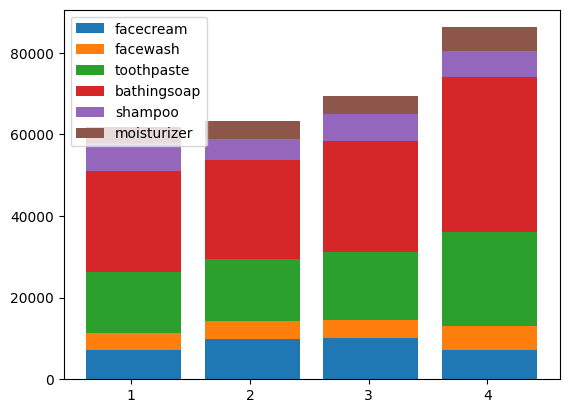

In [ ]:
# This list will store previously plotted columns
# It is used to calculate the bottom position for stacking
all_cols = []

# Loop through product columns only
for col in final_df.columns[1:7]:
    
    # If this is the FIRST product
    if len(all_cols) == 0:
        
        # Plot normally because nothing is below it
        plt.bar(
            final_df.index,      # X-axis: quarters
            final_df[col],       # Y-axis: sales of the product
            label=col            # Label for legend
        )
    
    # For all NEXT products
    else:
        
        # Stack bars on top of previous bars
        plt.bar(
            final_df.index,          # X-axis: quarters
            final_df[col],           # Current product sales
            bottom=sum(all_cols),    # Stack on top of previous products
            label=col
        )
    
    # Store current column values for next iteration
    all_cols.append(final_df[col])

# Fix x-axis ticks (quarter labels)
plt.xticks(final_df.index - 0.02, final_df.index)

# Show legend to identify products
plt.legend()

# Display the stacked bar chart
plt.show()


In [ ]:
sum(all_cols)